**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**13 | Final Development Training and Research Evidence Synthesis**

![HARTH final Development fitting and research evidence workflow](../../images/13_consolidated_workflow.svg)

**Objective:** Fit the Development-selected weighted 1D-ResNet and fixed Random Forest reference, preserve their inference configuration and synthesise the study's Development findings without treating training performance as independent validation.

**Dataset and cohort:** Pinned HARTH v2.0 recordings from **29 Development participants**, represented by **14,201** label-pure windows with six acceleration channels and eight target activity codes. The source selection applies a label-independent cap of 500 windows per participant. S023 and S032 are excluded from final fitting.

**Recorded execution:** The saved outputs show **400 Adam updates** of the weighted 1D-ResNet on a **CPU** runtime (67.65 seconds), followed by a **120-tree Random Forest** trained on 30 statistical features. Model artefacts were saved and reloaded for a 24-window Development inference check. These are fitting and engineering observations, not held-out performance estimates.

**Development evidence:** [Notebook 10](10_harth_advanced_temporal_architectures_and_matched_benchmark.ipynb) reports the seven-model matched comparison; [Notebook 11](11_harth_multiseed_stability_and_imbalance_robustness.ipynb) examines three-seed robustness and loss functions; [Notebook 12](12_harth_development_model_selection_and_protocol_specification.ipynb) records the primary/reference selection and evaluation specification. Source support and calibration findings are retained from Notebooks 09 and 08.

**Qualified evaluation boundary:** Earlier S023/S032 observations are qualified same-study evidence, not blind external validation. The original aligned historical prediction file was unavailable in this recorded execution, so this notebook neither re-scores Test participants nor reports historical Test metrics for the newly fitted models.

**Deliverables:** Development/research CSV tables, the training-loss figure and a single Colab download ZIP. The model bundle retains `resnet_state_dict.pt`, `random_forest.joblib` and human-readable `inference_config.csv`; no nested archive or administrative JSON is needed.

**00. Colab Repository Setup**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/human-movement-intelligence


**01. Imports and Research Environment**

In [ ]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ---------------------------- 2. Standard Library ----------------------------
from zipfile import ZIP_DEFLATED, ZipFile
from shutil import copyfile

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Machine Learning and Deep Learning -------------------
from sklearn.ensemble import RandomForestClassifier
from core.computer_device import computer_device
from core.harth_final_inference import (
    fit_final_resnet, save_final_models, load_final_models,
    infer_source_windows,
)
from core.harth_qualified_test_report import (
    summarise_qualified_heldout, SOURCE_CLASSES, RESERVED_PEOPLE,
)
from core.feature_engineering import extract_signal_features
from harth_data import (
    HARTH_REVISION, HARTH_SUBJECTS, SENSOR_COLUMNS, ACTIVITY_NAMES,
    prepare_harth_window_cohort,
)

# ------------------- 5. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)

# -------------------------- 6. Outputs and Compute Device --------------------
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
model_dir = root / "data" / "processed" / "harth_final_models"
model_dir.mkdir(parents=True, exist_ok=True)
raw_dir = root / "data" / "raw" / "harth_v2"
CLASSES = tuple(SOURCE_CLASSES)
RESERVED = set(RESERVED_PEOPLE)
DEVICE = str(computer_device(min_vram_gb=None))
print("Final Development device:", DEVICE)
print("Study outputs:", output_dir)

**02. Read Development Model Selection and Fitting Settings**

Load Notebook 12's exported source, model and evaluation specifications alongside the existing seven-model and robustness summaries from Notebooks 10 and 11. Confirm the selected weighted 1D-ResNet, 400 Adam updates, 120-tree Random Forest, pinned source revision and eight-class metric definition before fitting.

These files document Development selection and configured pipelines. They contain no newly fitted model predictions or independent performance estimates for the final Development fit.

In [3]:
# =============== 02. Read Model Selection and Fitting Settings ===============

# ----------------------- 1. Current Required Input Files ---------------------
input_files = {
    "selection": "12_development_model_selection_decisions.csv",
    "source": "12_recorded_source_protocol.csv",
    "training": "12_recorded_training_configuration.csv",
    "scope": "12_qualified_evaluation_scope.csv",
    "benchmark": "10_matched_cv_model_summary.csv",
    "robustness": "11_robustness_model_summary.csv",
}
absent = [name for name in input_files.values()
          if not (output_dir / name).is_file()]
if absent:
    raise FileNotFoundError(
        "Publish Notebook 12 CSV outputs before running Notebook 13: "
        + ", ".join(absent)
    )
tables = {key: pd.read_csv(output_dir / name)
          for key, name in input_files.items()}
source = tables["source"].set_index("property")["recorded_value"]
training = tables["training"].set_index("setting")["recorded_value"]
scope = tables["scope"].set_index("item")["recorded_rule"]

# ----------------------- 2. Check the Selected Recipe ------------------------
if (
    str(training["Primary architecture"]) != "1D-ResNet"
    or str(training["Reference"]) != "Random Forest"
    or str(training["Loss"]) != "inverse_sqrt_weighted_ce"
    or str(training["Optimiser"]) != "Adam"
    or int(training["Optimiser updates"]) != 400
    or int(training["Batch size"]) != 128
    or float(training["Learning rate"]) != 0.001
    or int(training["RF trees"]) != 120
    or int(training["RF minimum leaf"]) != 3
    or str(training["RF class weighting"]) != "balanced_subsample"
    or str(scope["Primary metric"]) != "Fixed-eight-class Macro F1"
):
    raise ValueError("Notebook 12 selected configuration differs.")
if str(source["Pinned revision"]) != HARTH_REVISION:
    raise ValueError("Pinned HARTH source revision differs.")
if str(source["Reserved participants"]) != "S023, S032":
    raise ValueError("Unexpected reserved participant assignments.")
if int(source["Window size (samples)"]) != 100 or int(
    source["Stride (samples)"]
) != 50:
    raise ValueError("Unexpected source window specification.")
protocol = {"primary_model": {
    "architecture": "1D-ResNet",
    "classes": list(CLASSES),
    "random_seed": int(training["Seed"]),
    "batch_size": int(training["Batch size"]),
    "learning_rate": float(training["Learning rate"]),
    "optimizer_steps": int(training["Optimiser updates"]),
}}
display(tables["selection"][["role", "configuration", "rationale"]])

,role,configuration,rationale
0,Primary model,1D-ResNet + inverse-sqrt Weighted CE,Highest observed mean Macro F1
1,Fixed classical reference,"Random Forest, 120 trees",Fixed classical comparator; stronger Shuffling F1
2,Development neural comparator,TCN + inverse-sqrt Weighted CE,Seed sensitivity and reference architecture co...
3,Exploratory ResNet loss alternatives,Focal and Class-Balanced Cross-Entropy,Lower mean Macro F1; minority-class precision/...


**03. Reconstruct the Development Cohort**

Prepare original HARTH v2.0 recordings from the **29 Development participants**, excluding S023 and S032 before source loading. The adapter forms fully labelled, timestamp-continuous 100-sample windows at a 50-sample stride; non-target activity codes are excluded after windowing, without reinterpreting undocumented source labels.

The saved output contains **14,201 windows**. Participant S009 contributes **201** eligible sampled windows; the other 28 Development participants contribute 500 each. Shuffling has **219** windows, Stairs ascending **192** and Stairs descending **182**. Window and label alignment, activity codes and participant coverage are checked before fitting.

Overlapping windows from the same participant are correlated. The participant, rather than the window, is the independent grouping unit in the preceding Development evaluations.

In [4]:
# ================== 03. Reconstruct the Development Cohort ===================

# -------------------- 1. Separate Participant Identities ---------------------
development_people = sorted(set(HARTH_SUBJECTS) - RESERVED)
if len(development_people) != 29 or RESERVED & set(development_people):
    raise ValueError("Unexpected Development participant split.")

# -------------------- 2. Prepare Original Source Windows ---------------------
X_dev, y_dev, metadata, cohort = prepare_harth_window_cohort(
    subjects=development_people, data_dir=raw_dir,
    task_classes=CLASSES,
    max_windows_per_subject=int(source["Development cap per person"]),
    window_size=int(source["Window size (samples)"]),
    step_size=int(source["Stride (samples)"]),
    sampling_rate=int(source["Sampling rate (Hz)"]),
)
if (X_dev.ndim != 3 or X_dev.shape[1:] != (6, 100)
        or len(X_dev) != len(y_dev) or len(metadata) != len(y_dev)):
    raise ValueError("Development window/source alignment failed.")
if set(metadata["subject_id"]) != set(development_people):
    raise ValueError("Incomplete or overlapping participant coverage.")
if not np.array_equal(y_dev, metadata["label"].to_numpy()):
    raise ValueError("Target labels are not aligned with signal windows.")
if not np.isin(y_dev, CLASSES).all() or not np.isfinite(X_dev).all():
    raise ValueError("Invalid input activity codes or sensor values.")
if len(X_dev) != int(source["Development windows"]):
    raise ValueError("Original Development selection differs from Notebook 12.")

# ----------------------- 3. Save Source-Level Support ------------------------
cohort.to_csv(output_dir / "13_development_cohort_summary.csv",
              index=False)
support = pd.DataFrame({
    "source_code": list(CLASSES),
    "activity": [ACTIVITY_NAMES[c] for c in CLASSES],
    "development_windows": [
        int(np.count_nonzero(y_dev == c)) for c in CLASSES
    ],
})
support.to_csv(output_dir / "13_development_activity_support.csv",
               index=False)
display(support)
print("Development participants:", len(development_people))
print("Development windows:", len(X_dev))

Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Downloaded 50,898,931 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 sa

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Downloaded 22,728,229 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Downloaded 16,070,724 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Downloaded 14,899,779 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Reje

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)


,source_code,activity,development_windows
0,1,Walking,3591
1,2,Running,1028
2,3,Shuffling,219
3,4,Stairs ascending,192
4,5,Stairs descending,182
5,6,Standing,2227
6,7,Sitting,5599
7,8,Lying,1163


Development participants: 29
Development windows: 14201


**04. Train the Final 1D-ResNet**

The selected 1D-ResNet is fitted to the full Development cohort using inverse-square-root weighted Cross-Entropy, seed **42**, Adam at learning rate **0.001**, batch size **128** and **400** optimiser updates. Per-channel scaling and class weights are calculated exclusively from Development, with the final-step checkpoint retained.

The saved run used a **CPU** runtime and recorded a fitting time of **67.65 seconds**. Logged training loss changed from **1.9961** at step 1 to **0.1291** at step 400; intermediate values were not monotonic. This trace describes fitting behaviour only and cannot be interpreted as participant-held-out accuracy or generalisation.

  Final 1D-ResNet: step 1/400 | Train loss=1.9961
  Final 1D-ResNet: step 100/400 | Train loss=0.3066
  Final 1D-ResNet: step 200/400 | Train loss=0.0779
  Final 1D-ResNet: step 300/400 | Train loss=0.0969
  Final 1D-ResNet: step 400/400 | Train loss=0.1291


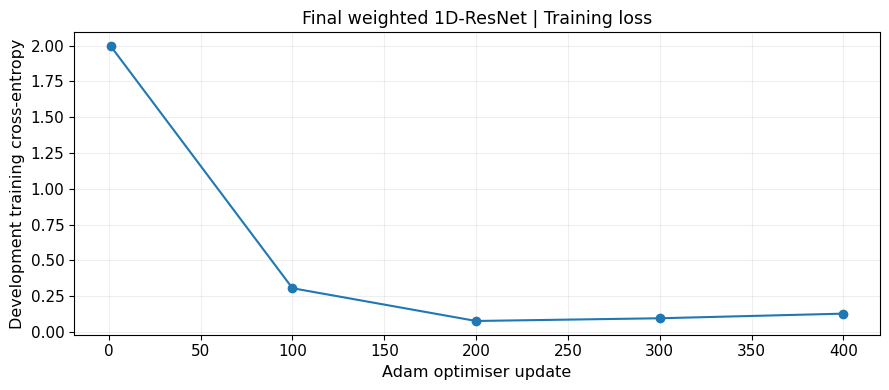

,step,development_train_loss
0,1,1.996078
1,100,0.306586
2,200,0.077936
3,300,0.096872
4,400,0.129093


Neural fitting time (seconds): 67.65


In [5]:
# ================== 04. Train the Final Weighted 1D-ResNet ===================

# ------------------- 1. Fit the Established Configuration --------------------
model, scaler, train_history, class_weights, fit_seconds = (
    fit_final_resnet(X_dev, y_dev, protocol, device=DEVICE)
)
if (train_history.empty or
        not np.isfinite(train_history["development_train_loss"]).all()):
    raise ValueError("Invalid Development training trace.")
if int(train_history["step"].iloc[-1]) != 400:
    raise ValueError("Final-step training record is incomplete.")

# ------------------- 2. Save Training and Scaler Evidence --------------------
train_history.to_csv(
    output_dir / "13_resnet_training_history.csv", index=False
)
pd.DataFrame({
    "channel": SENSOR_COLUMNS, "development_mean": scaler["mean"],
    "development_std": scaler["std"],
}).to_csv(output_dir / "13_development_channel_scaling.csv",
          index=False)
pd.DataFrame({
    "source_code": list(CLASSES),
    "activity": [ACTIVITY_NAMES[c] for c in CLASSES],
    "development_class_weight": np.asarray(class_weights).reshape(-1),
}).to_csv(output_dir / "13_resnet_class_weights.csv", index=False)

# ------------------------ 3. Plot Development Loss ---------------------------
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(train_history["step"],
        train_history["development_train_loss"], marker="o")
ax.set(xlabel="Adam optimiser update",
       ylabel="Development training cross-entropy",
       title="Final weighted 1D-ResNet | Training loss")
ax.grid(alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "13_resnet_training_loss.png")
plt.show()
display(train_history)
print("Neural fitting time (seconds):", round(fit_seconds, 2))

**05. Fit the Fixed Random Forest Reference**

Extract **30 deterministic features** from the same Development windows: mean, standard deviation, root-mean-square amplitude, peak-to-peak amplitude and waveform length for each of six acceleration channels. Fit the established Random Forest with **120 trees**, minimum leaf size **3**, balanced-subsample class weighting and random seed **42**.

The saved output confirms the resulting 30-column feature matrix and 120 fitted trees. No separate final-fit Test score is calculated. The historical comparison against ResNet comes from the participant-grouped Development benchmark, where the two pipelines use different signal representations.

In [6]:
# ==================== 05. Fit the Classical Random Forest ====================

# ---------------------- 1. Original-Unit Feature Matrix ----------------------
features = extract_signal_features(
    X_dev, channel_names=SENSOR_COLUMNS
)
if (features.shape != (len(X_dev), 30) or
        not np.isfinite(features.to_numpy()).all()):
    raise ValueError("Invalid Random Forest features.")

# ---------------------- 2. Fit the Classical Reference -----------------------
rf = RandomForestClassifier(
    n_estimators=int(training["RF trees"]),
    min_samples_leaf=int(training["RF minimum leaf"]),
    class_weight=str(training["RF class weighting"]),
    random_state=int(training["RF seed"]),
    n_jobs=-1,
)
rf.fit(features.to_numpy(), y_dev)
if set(rf.classes_) != set(CLASSES):
    raise ValueError("Missing fitted reference activity classes.")
print("Random Forest trees:", len(rf.estimators_))
print("Statistical features:", rf.n_features_in_)

Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Random Forest trees: 120
Statistical features: 30


**06. Save and Reload Reusable Model Artefacts**

Save the fitted ResNet weights as `resnet_state_dict.pt`, Random Forest as `random_forest.joblib`, and the ordered inference settings as `inference_config.csv`. The CSV records the six-channel order, source codes, Development-fitted means and standard deviations, statistical-feature order and model reconstruction settings. The configuration ensures that future inference applies the same fitted preprocessing.

The saved run reloads both local artefacts and checks predictions for **24 Development windows from S006**. It verifies Random Forest prediction equality before/after reload and valid ResNet source-code predictions. This is a software/inference consistency check on training data, **not** an independent evaluation of either model.

The configuration CSV is a model-use requirement, not a historical approval record. Model binaries must only be loaded from trusted sources and retained outside the temporary Colab runtime.

In [ ]:
# =================== 06. Save and Reload the Final Models ====================

# ------------------- 1. Store Development-Fitted Artefacts -------------------
artifacts = save_final_models(
    model, scaler, rf, list(features.columns), protocol, model_dir,
    source_revision=HARTH_REVISION,
)
if not all(path.is_file() for path in artifacts.values()):
    raise FileNotFoundError("A final trained model artefact is missing.")

# -------------------- 2. Export Human-Readable Settings ---------------------
config_csv = output_dir / "13_inference_config.csv"
copyfile(artifacts["config"], config_csv)
config_table = pd.read_csv(config_csv, dtype=str, keep_default_na=False)
if list(config_table.columns) != ["parameter", "position", "value"]:
    raise ValueError("The exported inference settings are not valid CSV.")
print("Inference settings exported:", config_csv)

# ---------------------- 2. Reload Trusted Local Models -----------------------
loaded_net, loaded_rf, config = load_final_models(
    model_dir, device="cpu"
)
if config["source_revision"] != HARTH_REVISION:
    raise ValueError("Saved source revision differs from the fitted cohort.")
if config["sensor_columns"] != list(SENSOR_COLUMNS):
    raise ValueError("Saved channel order differs from training.")
if config["feature_columns"] != list(features.columns):
    raise ValueError("Saved feature order differs from training.")
if list(loaded_rf.classes_) != list(CLASSES):
    raise ValueError("Reloaded model activity classes differ.")

# ----------------------- 3. Development-Only Inference -----------------------
n_check = min(24, len(y_dev))
pred_resnet, pred_rf = infer_source_windows(
    X_dev[:n_check], loaded_net, loaded_rf, config, device="cpu",
)
np.testing.assert_array_equal(
    pred_rf, rf.predict(features.iloc[:n_check].to_numpy())
)
if not set(pred_resnet).issubset(CLASSES):
    raise ValueError("ResNet returned invalid HARTH source codes.")
dev_check = pd.DataFrame({
    "subject_id": metadata["subject_id"].iloc[:n_check].to_numpy(),
    "true_development_code": y_dev[:n_check],
    "reloaded_resnet_prediction": pred_resnet,
    "reloaded_rf_prediction": pred_rf,
})
dev_check.to_csv(
    output_dir / "13_development_inference_example.csv", index=False
)
display(dev_check.head(10))

**07. Record the Final Fitting Procedure**

Export the selected settings and observed fitting information, including **29 participants**, **14,201 windows**, the weighted ResNet's **400-update** training budget, the **120-tree** classical reference and the **67.649-second** recorded neural fitting time.

These are source, configuration and engineering records. They must not be combined with the historical qualified Test scores as though the latter had been produced by the newly fitted models.

In [ ]:
# ================== 07. Summarise Final Development Fitting ==================

# ----------------------- 1. Save Current Run Settings ------------------------
training_summary = pd.DataFrame([
    ("HARTH source revision", HARTH_REVISION),
    ("Development participants", len(development_people)),
    ("Development windows", len(X_dev)),
    ("Activity classes", len(CLASSES)),
    ("ResNet loss", "inverse_sqrt_weighted_ce"),
    ("ResNet hidden channels", 32),
    ("ResNet optimiser", "Adam"),
    ("ResNet learning rate", float(training["Learning rate"])),
    ("ResNet batch size", int(training["Batch size"])),
    ("ResNet optimiser updates", 400),
    ("ResNet seed", int(training["Seed"])),
    ("Checkpoint", "final_step"),
    ("Random Forest trees", len(rf.estimators_)),
    ("Random Forest features", rf.n_features_in_),
    ("Neural fitting time (s)", round(fit_seconds, 3)),
    ("Reserved participants used for fitting", False),
], columns=["setting", "recorded_value"])
training_summary.to_csv(
    output_dir / "13_final_training_configuration.csv", index=False
)
display(training_summary)

,setting,recorded_value
0,HARTH source revision,dad2cfbe89a26f72f19770419469ac037de200df
1,Development participants,29
2,Development windows,14201
3,Activity classes,8
4,ResNet loss,inverse_sqrt_weighted_ce
5,ResNet hidden channels,32
6,ResNet optimiser,Adam
7,ResNet learning rate,0.001
8,ResNet batch size,128
9,ResNet optimiser updates,400


**08. Summarise Authentic Historical Qualified Evaluation Evidence**

The earlier HARTH evaluation concerned S023 and S032, which had already been inspected descriptively. Any original saved predictions from that evaluation should be interpreted as **qualified same-study held-out evidence**, not as a new blind or external Test.

This section accepts the historical file `25_qualified_aligned_predictions.csv` only when the original source-aligned labels and predictions exist. In the **recorded execution**, the file was unavailable; consequently, **no historical Test metrics were recalculated**, and the new Development-fitted models were not evaluated on reserved participants. The absence of these data does not justify inventing a score or transferring a previous model's score to the current artefacts.

**Historical findings preserved from the earlier executed assessment (not reproduced here):** The original weighted ResNet had fixed-eight-class Macro F1 **0.7182** and accuracy **0.9020**; the original Random Forest had Macro F1 **0.6817** and accuracy **0.9270** on 1,000 overlapping windows from S023/S032. True Shuffling, Stairs ascending and Stairs descending supports were only **3**, **10** and **6** windows, respectively. These are previously recorded results from the [historical Notebook 25 at revision bcffd956](https://github.com/RezaSaadatyar/human-movement-intelligence/blob/bcffd956dd3a89edd8eb23ad1f63e360a15c72b1/wearable_activity_recognition/code/notebooks/25_final_development_training_and_inference.ipynb), **not scores for the newly fitted Notebook 13 models**. They cannot be independently recalculated from the current `output/` folder because the original aligned predictions are not published.

In [ ]:
# ============== 08. Review Saved Qualified Evaluation Evidence ===============

# ---------------- 1. Clear This Stage's Optional Old Results -----------------
historical_owned = [
    "13_historical_qualified_model_summary.csv",
    "13_historical_qualified_per_subject.csv",
    "13_historical_qualified_per_class.csv",
    "13_historical_qualified_confusion_resnet.png",
    "13_historical_qualified_confusion_random_forest.png",
]
for filename in historical_owned:
    (output_dir / filename).unlink(missing_ok=True)

# --------------------- 2. Read Original Prediction Rows ----------------------
historical_path = output_dir / "25_qualified_aligned_predictions.csv"
historical_report = None
if historical_path.is_file():
    saved = pd.read_csv(historical_path)
    expected = {
        "subject_id", "true_source_code",
        "resnet_predicted_source_code",
        "random_forest_predicted_source_code",
    }
    if saved.empty or expected.difference(saved.columns):
        raise ValueError("Missing historical aligned prediction fields.")
    historical_preds = {
        "1D-ResNet Weighted CE":
            saved["resnet_predicted_source_code"].to_numpy(),
        "Random Forest":
            saved["random_forest_predicted_source_code"].to_numpy(),
    }

    # --------------------- 3. Recalculate Saved Metrics ----------------------
    historical_report = summarise_qualified_heldout(
        saved["true_source_code"].to_numpy(),
        saved["subject_id"].to_numpy(),
        historical_preds, ACTIVITY_NAMES, CLASSES,
    )
    for key, suffix in [
        ("summary", "model_summary"),
        ("per_subject", "per_subject"),
        ("per_class", "per_class"),
    ]:
        historical_report[key].to_csv(
            output_dir / ("13_historical_qualified_" + suffix + ".csv"),
            index=False,
        )
    display(historical_report["summary"].round(4))
    display(historical_report["per_subject"].round(4))
    print("Historical results recalculated from saved predictions.")
    print("The newly fitted Notebook 13 models were not Test-scored.")
else:
    print(
        "No original aligned qualified-Test CSV is available. "
        "No historical held-out metrics are reported."
    )

No original aligned qualified-Test CSV is available. No historical held-out metrics are reported.


**09. Visualise Historical Class-Level Evidence**

The plotting code can display eight-class confusion matrices from authentic, source-aligned historical predictions, preserving source-code order and count-based interpretation. These are historical qualified evaluation figures, separate from the new final-fit models.

In the saved run, no aligned historical prediction table was available, so **no qualified confusion matrices were generated**. The Development training-loss chart in Section 04 is not a substitute for held-out classification evidence.

In [ ]:
# ================ 09. Visualise Historical Qualified Evidence ================

# --------------------- 1. Plot Saved Eight-Class Counts ----------------------
if historical_report is not None:
    for model_name, cm in historical_report["confusion"].items():
        short = "resnet" if model_name.startswith("1D-") else "random_forest"
        fig, ax = plt.subplots(figsize=(8, 7))
        image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
        ax.set_xticks(range(8), list(map(str, CLASSES)))
        ax.set_yticks(range(8), list(map(str, CLASSES)))
        ax.set(
            xlabel="Predicted source code",
            ylabel="True source code",
            title="Historical qualified confusion | " + model_name,
        )
        for row in range(8):
            for column in range(8):
                ax.text(
                    column, row, str(int(cm[row, column])),
                    ha="center", va="center", fontsize=8,
                    color=("white" if cm[row, column] >
                           0.5 * cm.max() else "black"),
                )
        fig.colorbar(image, ax=ax, label="Window count")
        fig.tight_layout()
        save_figure(
            fig, output_dir /
            f"13_historical_qualified_confusion_{short}.png"
        )
        plt.show()
    subset = historical_report["per_class"].loc[
        lambda frame: frame["model"].eq("1D-ResNet Weighted CE"),
        ["source_code", "activity", "support"],
    ]
    display(subset)
else:
    print("No historical confusion figure without original predictions.")

No historical confusion figure without original predictions.


**10. Interpret Development and Cross-Stage Evidence**

The matched Development benchmark supports retaining weighted ResNet as the primary model and Random Forest as a classical reference. Notebook 11 adds three-seed and loss-function comparisons; Notebook 09 documents low support for Shuffling and stair activities. Model rankings are descriptive for the stated cohort and training conditions, not evidence of population-wide superiority.

In the separate Development calibration study from Notebook 08, mean ECE decreased from **0.0494 to 0.0286**, and mean Brier score from **0.1085 to 0.1044**, but mean NLL increased from **0.2494 to 0.2580**; mean accuracy remained **0.9275**. These are paired calibration comparisons within that experiment and should not be mixed with its separate confidence-audit model population. Temperature scaling was not applied to the final fitted ResNet.

**Limitations:** Participant count is modest; window overlap introduces dependence; Shuffling and stair activities have limited support. The historically reported S023/S032 scores came from a different executed final fit; this Notebook 13 run did not reproduce them, and its current fitted models have no independent held-out score. The original aligned predictions were unavailable in this execution. No external, prospective or clinical deployment performance is established.

In [ ]:
# ==================== 10. Synthesise Scientific Evidence =====================

# ---------------- 1. Display Existing Development Comparisons ----------------
display(tables["benchmark"].sort_values(
    "macro_f1_mean", ascending=False
)[["model", "macro_f1_mean", "macro_f1_sd"]].round(4))
display(tables["robustness"].sort_values(
    "mean_across_seed_fold_macro_f1", ascending=False
)[[
    "architecture", "loss_method",
    "mean_across_seed_fold_macro_f1", "across_seed_sd"
]].round(4))

# ------------------ 2. Distinguish Scientific Claim Levels -------------------
cal_file = output_dir / "08_calibration_mean_metrics.csv"
if cal_file.is_file():
    display(pd.read_csv(cal_file))
evidence_summary = pd.DataFrame([
    ("Development comparison",
     "Seven matched models and three-seed robustness",
     "Descriptive participant-grouped comparison"),
    ("Final model fitting",
     "Weighted ResNet and Random Forest fitted on Development",
     "Training and inference artefacts; no new Test score"),
    ("Rare-class behaviour",
     "Source support and Shuffling precision/recall contrasts",
     "Small class support and overlapping windows"),
    ("Calibration",
     "Mixed Development ECE/Brier/NLL response",
     "Not used for final fitted ResNet"),
    ("Historical qualified assessment",
     ("Aligned saved predictions available"
      if historical_report is not None else
      "No aligned saved predictions supplied"),
     "Two previously inspected participants; not blind external Test"),
    ("Broader applicability",
     "Independent validation is outside this evaluation",
     "No clinical deployment or population-wide claim"),
], columns=["topic", "evidence", "interpretation"])
evidence_summary.to_csv(
    output_dir / "13_research_evidence_summary.csv", index=False
)
display(evidence_summary)

,model,macro_f1_mean,macro_f1_sd
0,1D-ResNet,0.8336,0.0427
4,TCN,0.8138,0.0658
2,Random Forest,0.8094,0.0500
5,Time-Series Transformer,0.8006,0.0602
1,Multi-Scale CNN,0.7953,0.0483
6,Weighted CNN,0.7721,0.0269
3,Standard CNN,0.6660,0.0628


,architecture,loss_method,mean_across_seed_fold_macro_f1,across_seed_sd
2,1D-ResNet,weighted_ce,0.8289,0.0053
3,TCN,weighted_ce,0.8106,0.0078
1,1D-ResNet,focal,0.8057,0.0051
0,1D-ResNet,class_balanced,0.7915,0.0190


,method,nll,ece,brier,accuracy
0,Temperature scaled,0.258049,0.028621,0.104417,0.927505
1,Uncalibrated,0.249448,0.049417,0.108509,0.927505


,topic,evidence,interpretation
0,Development comparison,Seven matched models and three-seed robustness,Descriptive participant-grouped comparison
1,Final model fitting,Weighted ResNet and Random Forest fitted on De...,Training and inference artefacts; no new Test ...
2,Rare-class behaviour,Source support and Shuffling precision/recall ...,Small class support and overlapping windows
3,Calibration,Mixed Development ECE/Brier/NLL response,Not used for final fitted ResNet
4,Historical qualified assessment,No aligned saved predictions supplied,Two previously inspected participants; not bli...
5,Broader applicability,Independent validation is outside this evaluation,No clinical deployment or population-wide claim


**11. Export Final Model and Research Outputs**

The final export writes a **single ZIP** to the Colab file browser, containing `models/resnet_state_dict.pt`, `models/random_forest.joblib` and `models/inference_config.csv`, plus the stage's CSV and PNG files under `results/`. It does not create a second ZIP inside the download archive.

The separate `13_inference_config.csv` is also written to the study `output/` folder for readable, versioned inference settings. This is a flat table, with one parameter per row and indexed rows for ordered channels, classes, scaling statistics and features. The saved binary models remain necessary for inference; the CSV alone cannot reproduce trained weights.

The previously recorded run created nine research outputs (eight CSV files and one PNG) and an inner `13_model_artifacts.zip`. The updated export removes this obsolete inner ZIP locally and will produce the new configuration CSV and single download ZIP **when its changed cells are executed**. Historical Test tables are omitted if the original aligned prediction file is unavailable.

In [ ]:
# =================== 11. Export Final Models and Evidence ====================

# ------------------------- 1. Clear Obsolete Nested ZIP ----------------------
# A previous run placed a ZIP inside the general stage download bundle.
# The current stage writes one external archive, never a ZIP inside a ZIP.
(output_dir / "13_model_artifacts.zip").unlink(missing_ok=True)

# ----------------------- 2. Inventory Stage-Owned Results --------------------
stage_files = sorted(
    path for path in output_dir.iterdir()
    if path.is_file() and path.name.startswith("13_")
    and path.suffix.lower() in {".csv", ".png"}
)
required = {
    "13_development_cohort_summary.csv",
    "13_development_activity_support.csv",
    "13_development_channel_scaling.csv",
    "13_resnet_training_history.csv",
    "13_resnet_class_weights.csv",
    "13_resnet_training_loss.png",
    "13_development_inference_example.csv",
    "13_final_training_configuration.csv",
    "13_research_evidence_summary.csv",
    "13_inference_config.csv",
}
missing = required - {item.name for item in stage_files}
if missing:
    raise FileNotFoundError(
        "Missing outputs from the final Development fit: "
        + ", ".join(sorted(missing))
    )

# ------------------------- 3. Create One Download ZIP ------------------------
archive_root = Path("/content") if Path("/content").is_dir() else root.parent
bundle_path = (
    archive_root / "wearable_activity_recognition_Stage_13_Outputs.zip"
)
model_files = {
    "resnet_state_dict.pt": artifacts["resnet"],
    "random_forest.joblib": artifacts["reference"],
    "inference_config.csv": artifacts["config"],
}
with ZipFile(bundle_path, "w", compression=ZIP_DEFLATED) as bundle:
    for filename, file_path in model_files.items():
        if not file_path.is_file():
            raise FileNotFoundError("Missing trained model file: " + filename)
        bundle.write(file_path, arcname="models/" + filename)
    for path in stage_files:
        bundle.write(path, arcname="results/" + path.name)

# ---------------------- 4. Summarise Research Deliverables -------------------
print("Final Development participants:", len(development_people))
print("Final Development windows:", len(y_dev))
print("Historical Test results:", (
    "recalculated from authentic saved predictions"
    if historical_report is not None else "not recalculated in this run"
))
print("Model files: resnet_state_dict.pt, random_forest.joblib, "
      "inference_config.csv")
print("Current research CSV/PNG files:", len(stage_files))
print("Single ZIP download:", bundle_path)
print("No nested ZIP or original Test data included.")